# Exploración del featured RoCoLe (máscara COCO)

Objetivo: repetir el EDA del featured RoCoLe sobre la tabla con máscara COCO (índices RGB y textura GLCM solo dentro de la hoja): calidad, univariados, VARI, clases en train y correlaciones; decidir columnas para el baseline masked. Contraste mental con el 03 full-image. Sin entrenar modelos.


Fijamos la semilla para que lo que corramos después sea reproducible.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path


In [2]:
seed = 42

seed


42

Apuntamos a la tabla featured enmascarada de RoCoLe (rgb_glcm_features_masked.csv) y a la carpeta de figuras.


In [3]:
repo_root = Path("../..").resolve()
features_path = repo_root / "data" / "featured" / "rocole" / "rgb_glcm_features_masked.csv"
results_dir = repo_root / "experiments" / "results"
results_dir.mkdir(parents=True, exist_ok=True)

print("features_path:", features_path)
print("existe:", features_path.exists())
print("results_dir:", results_dir)
features_path, results_dir


features_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\rgb_glcm_features_masked.csv
existe: True
results_dir: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results


(WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/data/featured/rocole/rgb_glcm_features_masked.csv'),
 WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results'))

Leemos la tabla enmascarada: una fila por hoja, con etiqueta y medidas calculadas solo dentro de la máscara COCO Leaf.


In [4]:
leaf_features = pd.read_csv(features_path)

leaf_features.head()


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.466084,0.197243,0.250576,0.079053,0.348592,0.076514,0.684317,0.895943,0.381573
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.324993,0.094060,0.130550,0.068199,0.180603,0.094060,0.636574,0.897060,0.414018
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.427245,0.191211,0.199764,0.056161,0.272501,0.049086,0.650484,0.886744,0.405814
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.222965,0.062609,0.106283,0.021579,0.165645,0.029721,0.549393,0.927267,0.513788
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.237410,0.106820,0.062168,0.077000,0.085289,0.112395,0.660769,0.895654,0.415801


## Inspección de la tabla

Miramos cuántas filas y columnas hay, y las primeras filas.


In [5]:
# leaf_features

print("forma:", leaf_features.shape)
print("columnas:", list(leaf_features.columns))

leaf_features.head()


forma: (1481, 15)
columnas: ['File', 'split', 'link_group', 'Binary.Label', 'Multiclass.Label', 'error', 'exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'vari_mean', 'vari_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.466084,0.197243,0.250576,0.079053,0.348592,0.076514,0.684317,0.895943,0.381573
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.324993,0.094060,0.130550,0.068199,0.180603,0.094060,0.636574,0.897060,0.414018
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.427245,0.191211,0.199764,0.056161,0.272501,0.049086,0.650484,0.886744,0.405814
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.222965,0.062609,0.106283,0.021579,0.165645,0.029721,0.549393,0.927267,0.513788
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.237410,0.106820,0.062168,0.077000,0.085289,0.112395,0.660769,0.895654,0.415801


Revisamos si el mismo archivo aparece más de una vez. Si hay File repetido, hay que mirarlo antes de seguir.


In [6]:
# leaf_features

duplicate_files = leaf_features.loc[leaf_features["File"].duplicated(keep=False)].copy()

print("filas con File repetido:", len(duplicate_files))
print("Files únicos duplicados:", duplicate_files["File"].nunique() if len(duplicate_files) else 0)
duplicate_files.head()


filas con File repetido: 0
Files únicos duplicados: 0


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy


Contamos cuántas filas traen mensaje de error de extracción. Con máscara COCO puede haber fallos (máscara vacía o ausente) que no vimos en la versión full-image.


In [7]:
# leaf_features

error_series = leaf_features["error"].fillna("").astype(str).str.strip()
extraction_error_count = int((error_series != "").sum())

print("filas con error de extracción:", extraction_error_count)
extraction_error_count


filas con error de extracción: 0


C:\Users\victo\AppData\Local\Temp\ipykernel_25572\3114194739.py:3: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  error_series = leaf_features["error"].fillna("").astype(str).str.strip()


0

Nos quedamos con las filas sin error de extracción para el EDA de medidas. No tocamos el split: solo apartamos filas fallidas de máscara o extracción antes de mirar cajas, dispersiones y clases.


In [8]:
# leaf_features

error_mask = leaf_features["error"].fillna("").astype(str).str.strip() != ""
leaf_features_ok = leaf_features.loc[~error_mask].copy()
# A partir de aquí el EDA de medidas usa leaf_features = filas sin error
leaf_features = leaf_features_ok

print("filas originales con error:", int(error_mask.sum()))
print("filas para EDA (sin error):", len(leaf_features))
leaf_features_ok.head()


filas originales con error: 0
filas para EDA (sin error): 1481


C:\Users\victo\AppData\Local\Temp\ipykernel_25572\1878936759.py:3: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  error_mask = leaf_features["error"].fillna("").astype(str).str.strip() != ""


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.466084,0.197243,0.250576,0.079053,0.348592,0.076514,0.684317,0.895943,0.381573
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.324993,0.094060,0.130550,0.068199,0.180603,0.094060,0.636574,0.897060,0.414018
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.427245,0.191211,0.199764,0.056161,0.272501,0.049086,0.650484,0.886744,0.405814
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.222965,0.062609,0.106283,0.021579,0.165645,0.029721,0.549393,0.927267,0.513788
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.237410,0.106820,0.062168,0.077000,0.085289,0.112395,0.660769,0.895654,0.415801


Apartamos las nueve medidas numéricas: ExG, NGRDI, VARI y GLCM. Las etiquetas quedan fuera de esta lista.


In [9]:
# leaf_features

quality_columns = [
    "exg_mean",
    "exg_std",
    "ngrdi_mean",
    "ngrdi_std",
    "vari_mean",
    "vari_std",
    "glcm_contrast",
    "glcm_homogeneity",
    "glcm_energy",
]

quality_columns


['exg_mean',
 'exg_std',
 'ngrdi_mean',
 'ngrdi_std',
 'vari_mean',
 'vari_std',
 'glcm_contrast',
 'glcm_homogeneity',
 'glcm_energy']

Contamos nulos por columna en toda la tabla filtrada, con foco en las nueve medidas.


In [10]:
null_counts = leaf_features.isna().sum()
missing_counts_all = leaf_features[quality_columns].isna().sum()

print("nulos en toda la tabla (sin error de extracción):")
print(null_counts)
print("\nnulos en las nueve medidas:")
print(missing_counts_all)
missing_counts_all


nulos en toda la tabla (sin error de extracción):
File                   0
split                  0
link_group             0
Binary.Label           0
Multiclass.Label       0
error               1481
exg_mean               0
exg_std                0
ngrdi_mean             0
ngrdi_std              0
vari_mean              0
vari_std               0
glcm_contrast          0
glcm_homogeneity       0
glcm_energy            0
dtype: int64

nulos en las nueve medidas:
exg_mean            0
exg_std             0
ngrdi_mean          0
ngrdi_std           0
vari_mean           0
vari_std            0
glcm_contrast       0
glcm_homogeneity    0
glcm_energy         0
dtype: int64


exg_mean            0
exg_std             0
ngrdi_mean          0
ngrdi_std           0
vari_mean           0
vari_std            0
glcm_contrast       0
glcm_homogeneity    0
glcm_energy         0
dtype: int64

Contamos valores no finitos en las nueve medidas.


In [11]:
# leaf_features, quality_columns

infinite_counts_all = {
    column: int((~np.isfinite(leaf_features[column])).sum())
    for column in quality_columns
}

print("no finitos por medida:")
for column, count in infinite_counts_all.items():
    print(f"  {column}: {count}")
infinite_counts_all


no finitos por medida:
  exg_mean: 0
  exg_std: 0
  ngrdi_mean: 0
  ngrdi_std: 0
  vari_mean: 0
  vari_std: 0
  glcm_contrast: 0
  glcm_homogeneity: 0
  glcm_energy: 0


{'exg_mean': 0,
 'exg_std': 0,
 'ngrdi_mean': 0,
 'ngrdi_std': 0,
 'vari_mean': 0,
 'vari_std': 0,
 'glcm_contrast': 0,
 'glcm_homogeneity': 0,
 'glcm_energy': 0}

Miramos la distribución de ExG con diagramas de caja. Solo observamos; no cortamos outliers. Figura con prefijo de enmascarado.


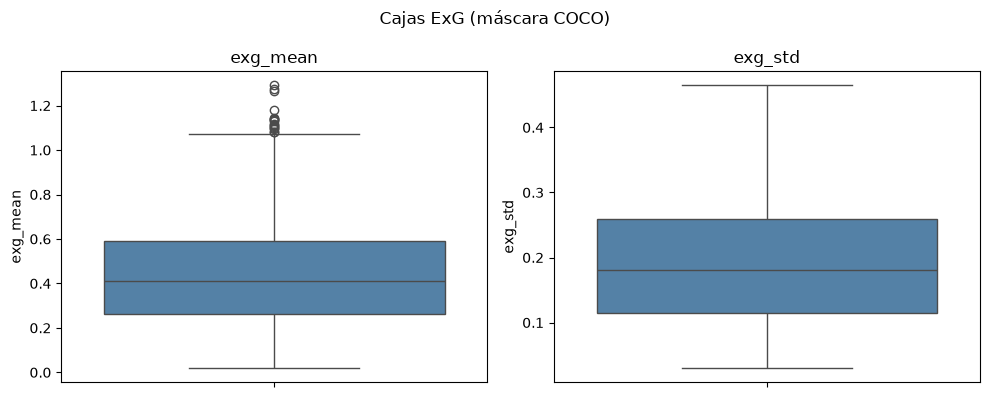

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-exg-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-exg-boxplots.png')

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["exg_mean", "exg_std"]):
    sns.boxplot(y=leaf_features[column], ax=axis, color="steelblue")
    axis.set_title(column)
fig.suptitle("Cajas ExG (máscara COCO)")
fig.tight_layout()
exg_box_path = results_dir / "rocole-featured-masked-exg-boxplots.png"
fig.savefig(exg_box_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", exg_box_path)
exg_box_path


Misma mirada univariada de ExG en dispersión: cada punto es una hoja.


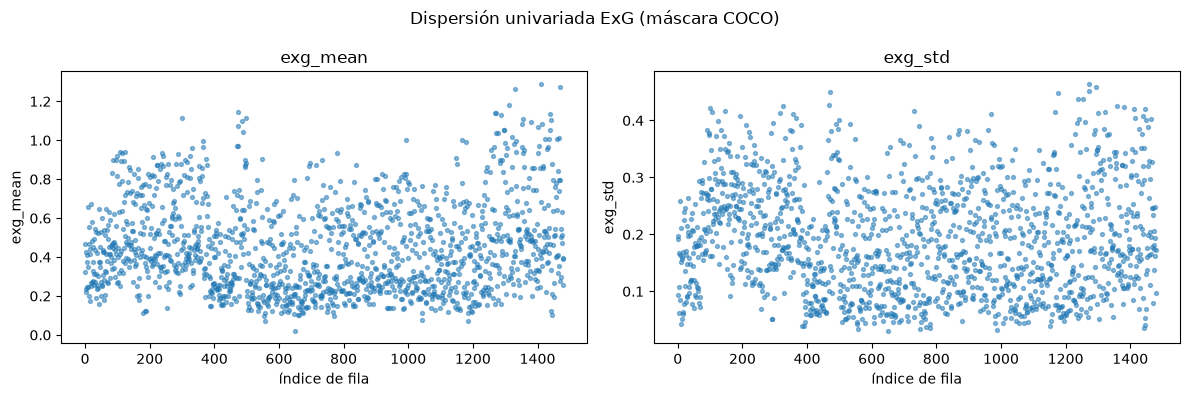

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-exg-scatter.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-exg-scatter.png')

In [13]:
# leaf_features

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
row_index = np.arange(len(leaf_features))
for axis, column in zip(axes, ["exg_mean", "exg_std"]):
    axis.scatter(row_index, leaf_features[column], s=8, alpha=0.5)
    axis.set_xlabel("índice de fila")
    axis.set_ylabel(column)
    axis.set_title(column)
fig.suptitle("Dispersión univariada ExG (máscara COCO)")
fig.tight_layout()
exg_scatter_path = results_dir / "rocole-featured-masked-exg-scatter.png"
fig.savefig(exg_scatter_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", exg_scatter_path)
exg_scatter_path


Ahora las cajas de NGRDI, misma mirada univariada.


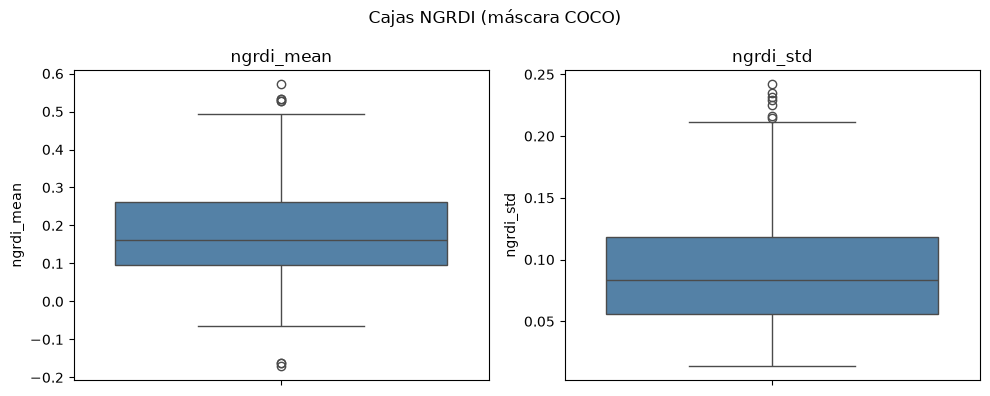

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-ngrdi-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-ngrdi-boxplots.png')

In [14]:
# leaf_features

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["ngrdi_mean", "ngrdi_std"]):
    sns.boxplot(y=leaf_features[column], ax=axis, color="steelblue")
    axis.set_title(column)
fig.suptitle("Cajas NGRDI (máscara COCO)")
fig.tight_layout()
ngrdi_box_path = results_dir / "rocole-featured-masked-ngrdi-boxplots.png"
fig.savefig(ngrdi_box_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", ngrdi_box_path)
ngrdi_box_path


Dispersión univariada de NGRDI, una hoja por punto.


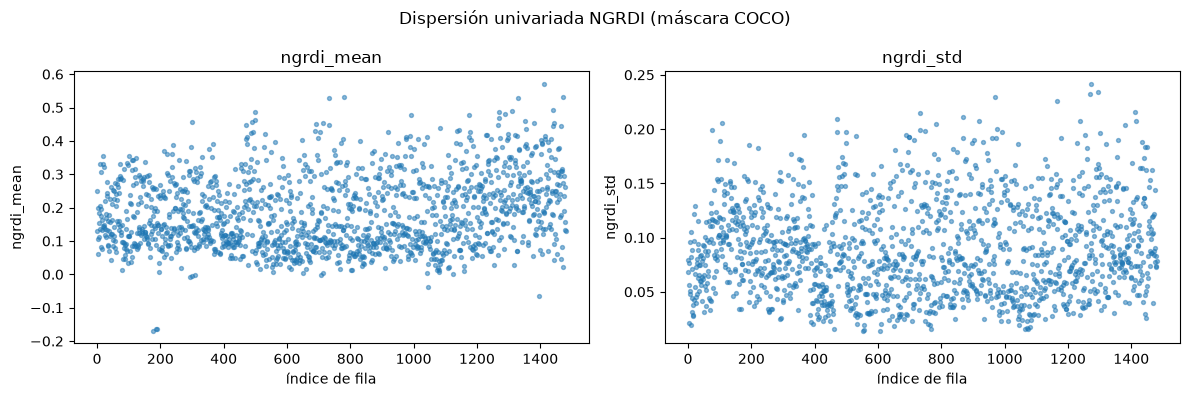

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-ngrdi-scatter.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-ngrdi-scatter.png')

In [15]:
# leaf_features

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, column in zip(axes, ["ngrdi_mean", "ngrdi_std"]):
    axis.scatter(row_index, leaf_features[column], s=8, alpha=0.5)
    axis.set_xlabel("índice de fila")
    axis.set_ylabel(column)
    axis.set_title(column)
fig.suptitle("Dispersión univariada NGRDI (máscara COCO)")
fig.tight_layout()
ngrdi_scatter_path = results_dir / "rocole-featured-masked-ngrdi-scatter.png"
fig.savefig(ngrdi_scatter_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", ngrdi_scatter_path)
ngrdi_scatter_path


Cajas de VARI. Pueden verse aplastadas por extremos; aquí solo miramos, sin decidir todavía.


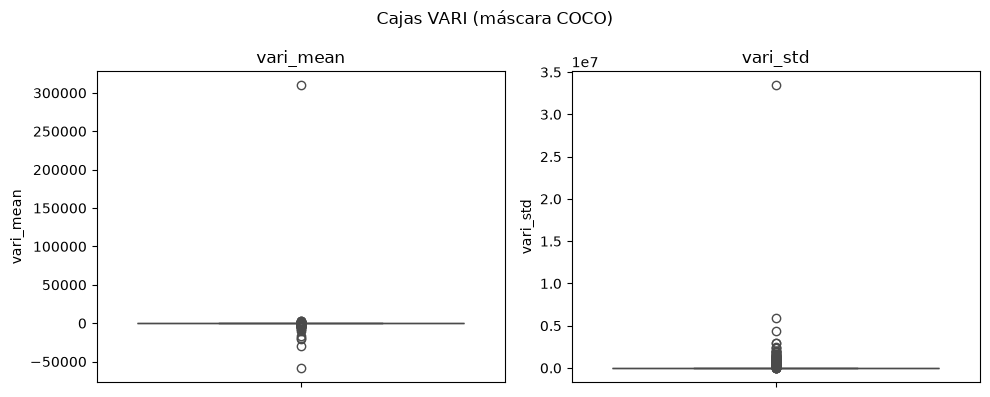

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-vari-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-vari-boxplots.png')

In [16]:
# leaf_features

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["vari_mean", "vari_std"]):
    sns.boxplot(y=leaf_features[column], ax=axis, color="steelblue")
    axis.set_title(column)
fig.suptitle("Cajas VARI (máscara COCO)")
fig.tight_layout()
vari_box_path = results_dir / "rocole-featured-masked-vari-boxplots.png"
fig.savefig(vari_box_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", vari_box_path)
vari_box_path


Dispersión univariada de VARI. Los extremos saltan a la vista; seguimos observando.


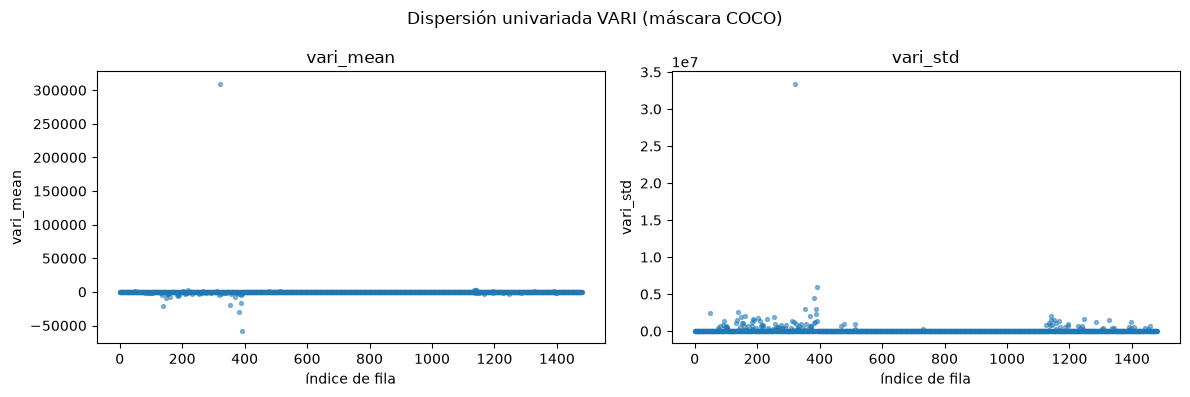

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-vari-scatter.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-vari-scatter.png')

In [17]:
# leaf_features

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, column in zip(axes, ["vari_mean", "vari_std"]):
    axis.scatter(row_index, leaf_features[column], s=8, alpha=0.5)
    axis.set_xlabel("índice de fila")
    axis.set_ylabel(column)
    axis.set_title(column)
fig.suptitle("Dispersión univariada VARI (máscara COCO)")
fig.tight_layout()
vari_scatter_path = results_dir / "rocole-featured-masked-vari-scatter.png"
fig.savefig(vari_scatter_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", vari_scatter_path)
vari_scatter_path


Documentamos VARI solo en train con percentiles y extremos. La pregunta es si con máscara el denominador sigue rompiendo las colas, frente a lo visto en el 03 full-image.


In [18]:
# leaf_features, seed

train_leaves = leaf_features.loc[leaf_features["split"] == "train"].copy()
percentile_levels = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
vari_mean_percentiles = train_leaves["vari_mean"].quantile(percentile_levels)
vari_std_percentiles = train_leaves["vari_std"].quantile(percentile_levels)
vari_mean_extremes = {
    "min": float(train_leaves["vari_mean"].min()),
    "max": float(train_leaves["vari_mean"].max()),
    "min_file": train_leaves.loc[train_leaves["vari_mean"].idxmin(), "File"],
    "max_file": train_leaves.loc[train_leaves["vari_mean"].idxmax(), "File"],
}
vari_std_extremes = {
    "min": float(train_leaves["vari_std"].min()),
    "max": float(train_leaves["vari_std"].max()),
    "min_file": train_leaves.loc[train_leaves["vari_std"].idxmin(), "File"],
    "max_file": train_leaves.loc[train_leaves["vari_std"].idxmax(), "File"],
}

print("train filas:", len(train_leaves))
print("\nvari_mean percentiles:")
print(vari_mean_percentiles)
print("\nvari_mean extremos:", vari_mean_extremes)
print("\nvari_std percentiles:")
print(vari_std_percentiles)
print("\nvari_std extremos:", vari_std_extremes)
vari_mean_percentiles


train filas: 1037

vari_mean percentiles:
0.01   -3605.607829
0.05    -439.893822
0.25       0.120280
0.50       0.205107
0.75       0.327100
0.95       0.479436
0.99      98.642224
Name: vari_mean, dtype: float64

vari_mean extremos: {'min': -58359.35126910388, 'max': 309664.69340271695, 'min_file': 'C10P21E1.jpg', 'max_file': 'C3P21E2.jpg'}

vari_std percentiles:
0.01    2.897853e-02
0.05    4.110076e-02
0.25    7.143264e-02
0.50    1.019754e-01
0.75    1.426734e-01
0.95    5.195497e+05
0.99    1.789606e+06
Name: vari_std, dtype: float64

vari_std extremos: {'min': 0.018930128644435867, 'max': 33420796.451869175, 'min_file': 'C9P10E2.jpg', 'max_file': 'C3P21E2.jpg'}


0.01   -3605.607829
0.05    -439.893822
0.25       0.120280
0.50       0.205107
0.75       0.327100
0.95       0.479436
0.99      98.642224
Name: vari_mean, dtype: float64

Con esa evidencia documentamos la decisión sobre VARI para el protocolo masked. El CSV puede conservar las columnas; el baseline masked solo usará lo que decidamos aquí. Si las colas siguen rotas como en el 03 full-image, la decisión esperada es drop_vari; confírmalo al correr con los percentiles enmascarados.


In [19]:
# vari_mean_percentiles, vari_std_percentiles

# Los percentiles del run confirman drop_vari (colas extremas en train masked); sin lógica condicional extra
vari_feature_decision = "drop_vari"

print("vari_feature_decision:", vari_feature_decision)
vari_feature_decision


vari_feature_decision: drop_vari


'drop_vari'

Si la decisión fue retirar VARI, listamos las siete columnas candidatas al baseline masked. Si se mantiene, esta lista incluiría VARI.


In [20]:
# vari_feature_decision, quality_columns

if vari_feature_decision == "drop_vari":
    baseline_feature_columns = [
        "exg_mean",
        "exg_std",
        "ngrdi_mean",
        "ngrdi_std",
        "glcm_contrast",
        "glcm_homogeneity",
        "glcm_energy",
    ]
else:
    baseline_feature_columns = list(quality_columns)

print("baseline_feature_columns:", baseline_feature_columns)
baseline_feature_columns


baseline_feature_columns: ['exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']


['exg_mean',
 'exg_std',
 'ngrdi_mean',
 'ngrdi_std',
 'glcm_contrast',
 'glcm_homogeneity',
 'glcm_energy']

Cajas univariadas de las tres medidas GLCM: contraste, homogeneidad y energía.


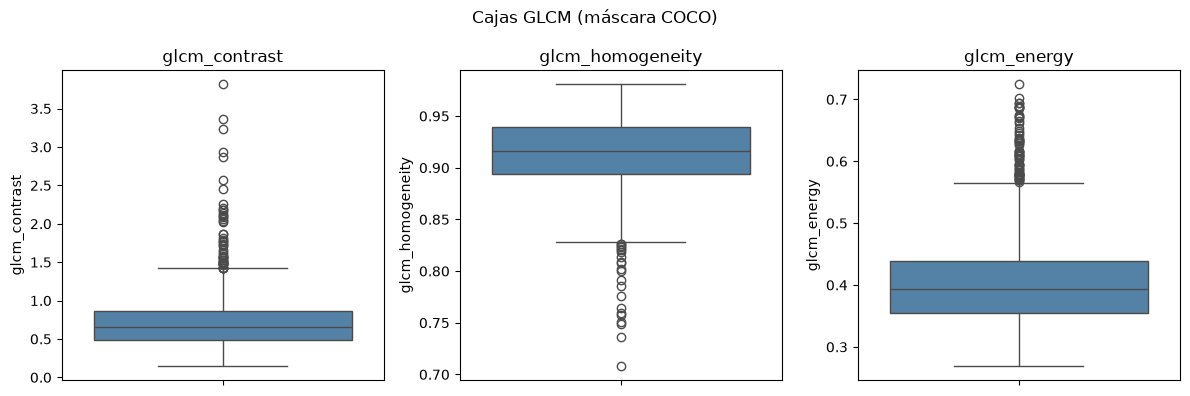

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-glcm-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-glcm-boxplots.png')

In [21]:
# leaf_features

glcm_columns = ["glcm_contrast", "glcm_homogeneity", "glcm_energy"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for axis, column in zip(axes, glcm_columns):
    sns.boxplot(y=leaf_features[column], ax=axis, color="steelblue")
    axis.set_title(column)
fig.suptitle("Cajas GLCM (máscara COCO)")
fig.tight_layout()
glcm_box_path = results_dir / "rocole-featured-masked-glcm-boxplots.png"
fig.savefig(glcm_box_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", glcm_box_path)
glcm_box_path


Dispersión univariada de las medidas GLCM.


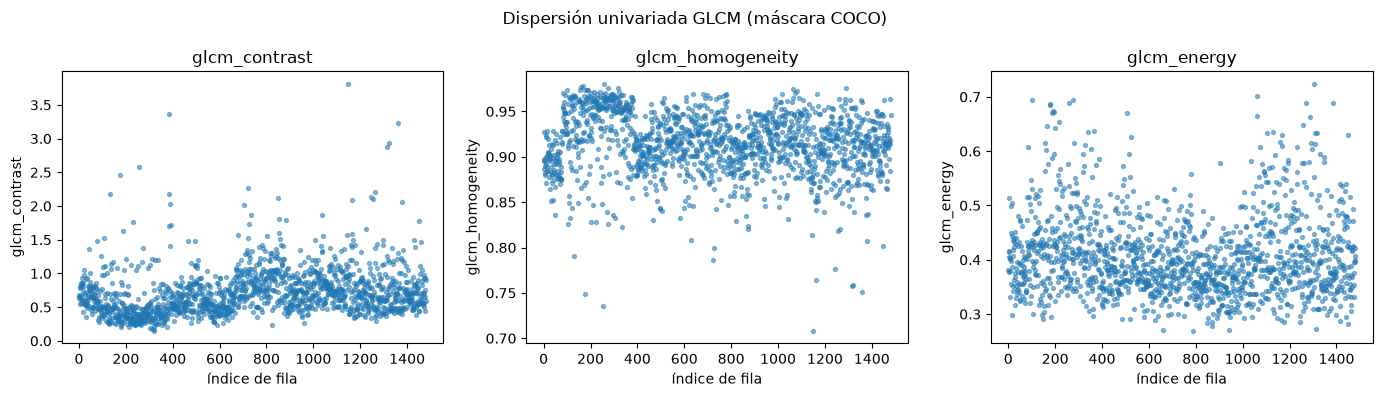

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-glcm-scatter.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-glcm-scatter.png')

In [22]:
# leaf_features

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, glcm_columns):
    axis.scatter(row_index, leaf_features[column], s=8, alpha=0.5)
    axis.set_xlabel("índice de fila")
    axis.set_ylabel(column)
    axis.set_title(column)
fig.suptitle("Dispersión univariada GLCM (máscara COCO)")
fig.tight_layout()
glcm_scatter_path = results_dir / "rocole-featured-masked-glcm-scatter.png"
fig.savefig(glcm_scatter_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", glcm_scatter_path)
glcm_scatter_path


Hasta aquí: carga, calidad, univariados y decisión VARI sobre el protocolo masked. Siguiente: comparar sanas y afectadas solo en train.


Nos quedamos con las filas de aprender, si aún no estaban apartadas. No tocamos el split.


In [23]:
# leaf_features

train_leaves = leaf_features.loc[leaf_features["split"] == "train"].copy()

print("train filas:", len(train_leaves))
train_leaves.head()


train filas: 1037


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.466084,0.197243,0.250576,0.079053,0.348592,0.076514,0.684317,0.895943,0.381573
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.324993,0.094060,0.130550,0.068199,0.180603,0.094060,0.636574,0.897060,0.414018
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.427245,0.191211,0.199764,0.056161,0.272501,0.049086,0.650484,0.886744,0.405814
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.222965,0.062609,0.106283,0.021579,0.165645,0.029721,0.549393,0.927267,0.513788
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.237410,0.106820,0.062168,0.077000,0.085289,0.112395,0.660769,0.895654,0.415801


Contamos cuántas hojas de train hay por Binary.Label.


In [24]:
# train_leaves

train_label_counts = train_leaves["Binary.Label"].value_counts()

print(train_label_counts)
train_label_counts


Binary.Label
healthy      530
unhealthy    507
Name: count, dtype: int64


Binary.Label
healthy      530
unhealthy    507
Name: count, dtype: int64

Elegimos las columnas a comparar por clase: las mismas que quedaron en la lista del baseline. Sin VARI si se decidió retirarla.


In [25]:
# baseline_feature_columns

comparison_columns = list(baseline_feature_columns)

comparison_columns


['exg_mean',
 'exg_std',
 'ngrdi_mean',
 'ngrdi_std',
 'glcm_contrast',
 'glcm_homogeneity',
 'glcm_energy']

Miramos ExG con cajas lado a lado por Binary.Label, solo en train.


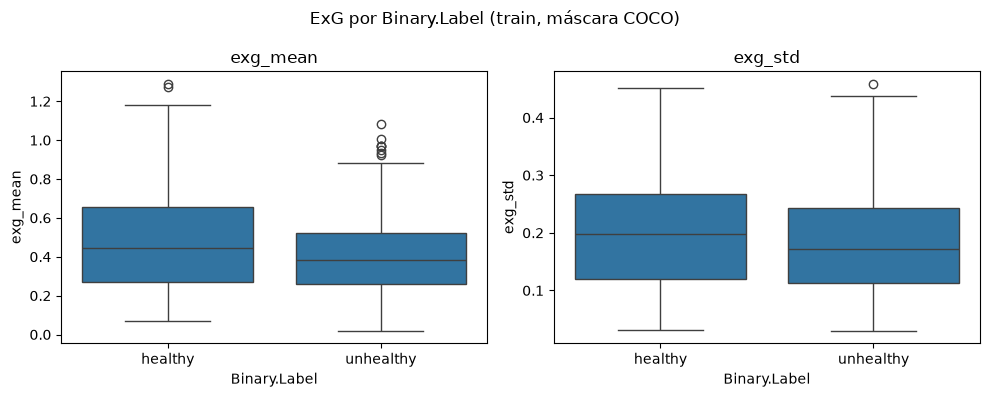

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-exg-by-label-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-exg-by-label-boxplots.png')

In [26]:
# train_leaves

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["exg_mean", "exg_std"]):
    sns.boxplot(data=train_leaves, x="Binary.Label", y=column, ax=axis)
    axis.set_title(column)
fig.suptitle("ExG por Binary.Label (train, máscara COCO)")
fig.tight_layout()
exg_by_label_path = results_dir / "rocole-featured-masked-exg-by-label-boxplots.png"
fig.savefig(exg_by_label_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", exg_by_label_path)
exg_by_label_path


Lectura ExG: mira si las cajas se solapan o se apartan. Es visual; no es veredicto de predicción. Contrasta mentalmente con lo que viste en el 03 full-image.


Misma comparación con NGRDI por Binary.Label en train.


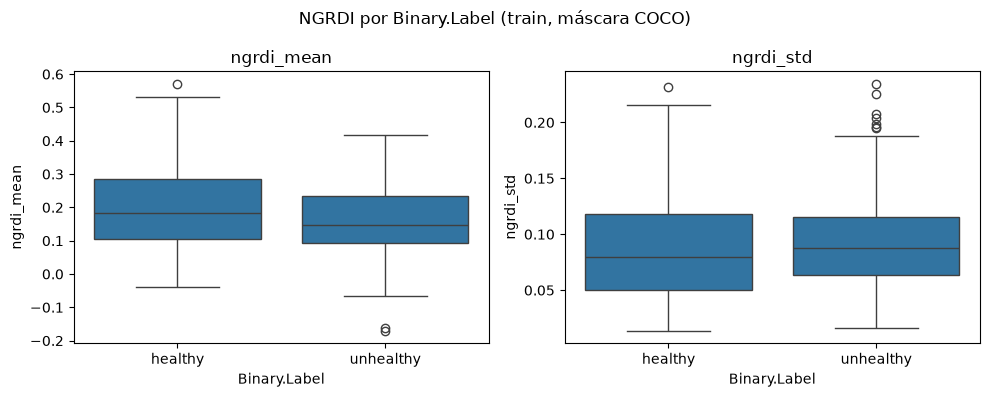

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-ngrdi-by-label-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-ngrdi-by-label-boxplots.png')

In [27]:
# train_leaves

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, column in zip(axes, ["ngrdi_mean", "ngrdi_std"]):
    sns.boxplot(data=train_leaves, x="Binary.Label", y=column, ax=axis)
    axis.set_title(column)
fig.suptitle("NGRDI por Binary.Label (train, máscara COCO)")
fig.tight_layout()
ngrdi_by_label_path = results_dir / "rocole-featured-masked-ngrdi-by-label-boxplots.png"
fig.savefig(ngrdi_by_label_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", ngrdi_by_label_path)
ngrdi_by_label_path


Lectura NGRDI: otra vez, mira el solape o la separación. No es un ranking de variables.


Ahora las tres medidas GLCM por clase en train.


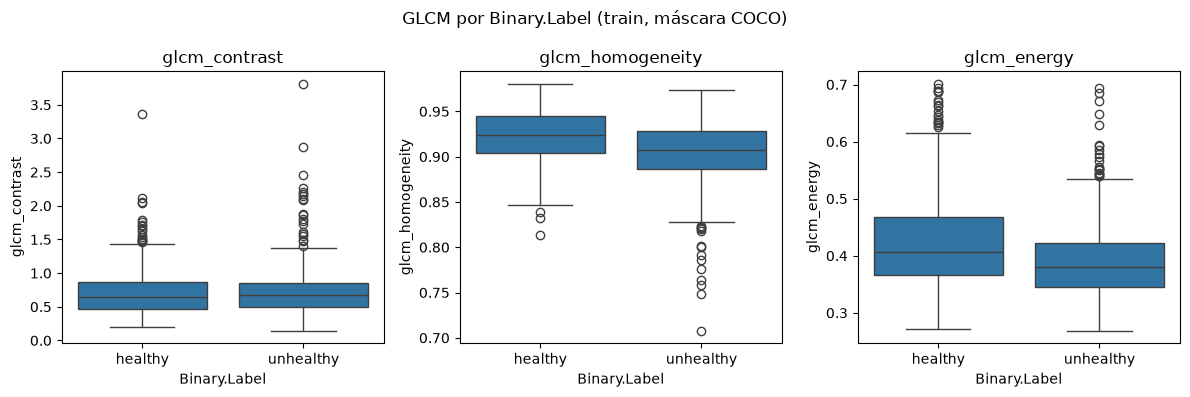

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-glcm-by-label-boxplots.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-glcm-by-label-boxplots.png')

In [28]:
# train_leaves

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for axis, column in zip(axes, ["glcm_contrast", "glcm_homogeneity", "glcm_energy"]):
    sns.boxplot(data=train_leaves, x="Binary.Label", y=column, ax=axis)
    axis.set_title(column)
fig.suptitle("GLCM por Binary.Label (train, máscara COCO)")
fig.tight_layout()
glcm_by_label_path = results_dir / "rocole-featured-masked-glcm-by-label-boxplots.png"
fig.savefig(glcm_by_label_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", glcm_by_label_path)
glcm_by_label_path


Lectura GLCM: observa si alguna medida se aparta un poco entre clases o si casi todo se solapa.


Vimos solape o separación a ojo en train. Aún no medimos acierto. Pregunta abierta: ¿la máscara mejoró la separación frente al 03 full-image?


Comprobamos en train que etiqueta, split y link_group coinciden con el índice featured, fila a fila por File. No rehacemos el split.


In [29]:
# train_leaves

index_path = repo_root / "data" / "featured" / "rocole" / "index.csv"
featured_index = pd.read_csv(index_path)
train_with_index = train_leaves.merge(
    featured_index[["File", "Binary.Label", "split", "link_group"]],
    on="File",
    how="left",
    suffixes=("_feat", "_index"),
)
label_match = (
    train_with_index["Binary.Label_feat"] == train_with_index["Binary.Label_index"]
).all()
split_match = (train_with_index["split_feat"] == train_with_index["split_index"]).all()
link_match = (
    train_with_index["link_group_feat"] == train_with_index["link_group_index"]
).all()
missing_in_index = int(train_with_index["split_index"].isna().sum())
index_integrity = {
    "train_rows": len(train_leaves),
    "merged_rows": len(train_with_index),
    "missing_in_index": missing_in_index,
    "Binary.Label_match": bool(label_match),
    "split_match": bool(split_match),
    "link_group_match": bool(link_match),
}

print(index_integrity)
index_integrity


{'train_rows': 1037, 'merged_rows': 1037, 'missing_in_index': 0, 'Binary.Label_match': True, 'split_match': True, 'link_group_match': True}


{'train_rows': 1037,
 'merged_rows': 1037,
 'missing_in_index': 0,
 'Binary.Label_match': True,
 'split_match': True,
 'link_group_match': True}

Antes de cerrar, miramos relaciones entre medidas y con la etiqueta. Solo train. Sin VARI si quedó drop_vari. Observamos; no coronamos predictoras.


Pasamos la etiqueta binaria a números para correlacionar: sana vale 0 y afectada vale 1.


In [30]:
# train_leaves

binary_label_code = train_leaves["Binary.Label"].map(
    {"healthy": 0, "unhealthy": 1}
)

print(binary_label_code.value_counts(dropna=False))
binary_label_code


Binary.Label
0    530
1    507
Name: count, dtype: int64


0       0
1       1
2       0
3       0
4       1
       ..
1475    0
1476    1
1477    0
1478    1
1479    1
Name: Binary.Label, Length: 1037, dtype: int64

Armamos una tabla de train con las columnas de comparación más el código 0/1.


In [31]:
# train_leaves, comparison_columns, binary_label_code

correlation_leaves = train_leaves[comparison_columns].copy()
correlation_leaves["binary_label_code"] = binary_label_code.to_numpy()

correlation_leaves.head()


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy,binary_label_code
0,0.466084,0.197243,0.250576,0.079053,0.684317,0.895943,0.381573,0
1,0.324993,0.094060,0.130550,0.068199,0.636574,0.897060,0.414018,1
2,0.427245,0.191211,0.199764,0.056161,0.650484,0.886744,0.405814,0
3,0.222965,0.062609,0.106283,0.021579,0.549393,0.927267,0.513788,0
4,0.237410,0.106820,0.062168,0.077000,0.660769,0.895654,0.415801,1


Correlación de cada medida con el código de etiqueta. Miramos magnitud y signo; no es ranking de predictoras.


In [32]:
# correlation_leaves

feature_label_correlation = correlation_leaves[comparison_columns].corrwith(
    correlation_leaves["binary_label_code"]
)

print(feature_label_correlation)
feature_label_correlation


exg_mean           -0.169453
exg_std            -0.075572
ngrdi_mean         -0.173737
ngrdi_std           0.053224
glcm_contrast       0.046176
glcm_homogeneity   -0.253542
glcm_energy        -0.224693
dtype: float64


exg_mean           -0.169453
exg_std            -0.075572
ngrdi_mean         -0.173737
ngrdi_std           0.053224
glcm_contrast       0.046176
glcm_homogeneity   -0.253542
glcm_energy        -0.224693
dtype: float64

Lee esos números. Si salen bajos, encaja con el solape de las cajas.


Ahora la relación entre medidas: matriz de correlación solo entre las características de comparación, sin la etiqueta.


In [33]:
# correlation_leaves, comparison_columns

feature_correlation_matrix = correlation_leaves[comparison_columns].corr()

feature_correlation_matrix


,exg_mean,exg_std,ngrdi_mean,ngrdi_std,glcm_contrast,glcm_homogeneity,glcm_energy
exg_mean,1.000000,0.838737,0.849089,0.718215,0.082825,-0.041640,-0.214677
exg_std,0.838737,1.000000,0.713842,0.890535,0.216222,-0.200747,-0.272980
ngrdi_mean,0.849089,0.713842,1.000000,0.722516,0.114366,-0.101755,-0.276058
ngrdi_std,0.718215,0.890535,0.722516,1.000000,0.294495,-0.293056,-0.339385
glcm_contrast,0.082825,0.216222,0.114366,0.294495,1.000000,-0.671233,-0.273934
glcm_homogeneity,-0.041640,-0.200747,-0.101755,-0.293056,-0.671233,1.000000,0.527967
glcm_energy,-0.214677,-0.272980,-0.276058,-0.339385,-0.273934,0.527967,1.000000


Pintamos esa matriz como mapa de calor.


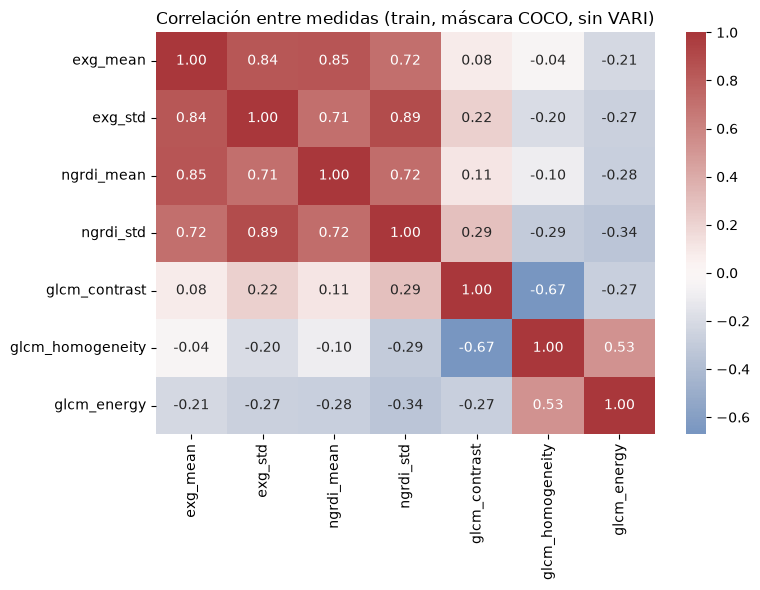

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-feature-corr-heatmap.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-feature-corr-heatmap.png')

In [34]:
# feature_correlation_matrix, results_dir

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    feature_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    ax=ax,
)
ax.set_title("Correlación entre medidas (train, máscara COCO, sin VARI)")
fig.tight_layout()
feature_corr_heatmap_path = results_dir / "rocole-featured-masked-feature-corr-heatmap.png"
fig.savefig(feature_corr_heatmap_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", feature_corr_heatmap_path)
feature_corr_heatmap_path


Para no saturar la figura, elegimos unas pocas medidas de familias distintas: media de ExG, media de NGRDI y contraste GLCM.


In [35]:
pair_feature_columns = ["exg_mean", "ngrdi_mean", "glcm_contrast"]

pair_feature_columns


['exg_mean', 'ngrdi_mean', 'glcm_contrast']

Gráficos de pares solo con ese subconjunto, en train, coloreados por sana/afectada.


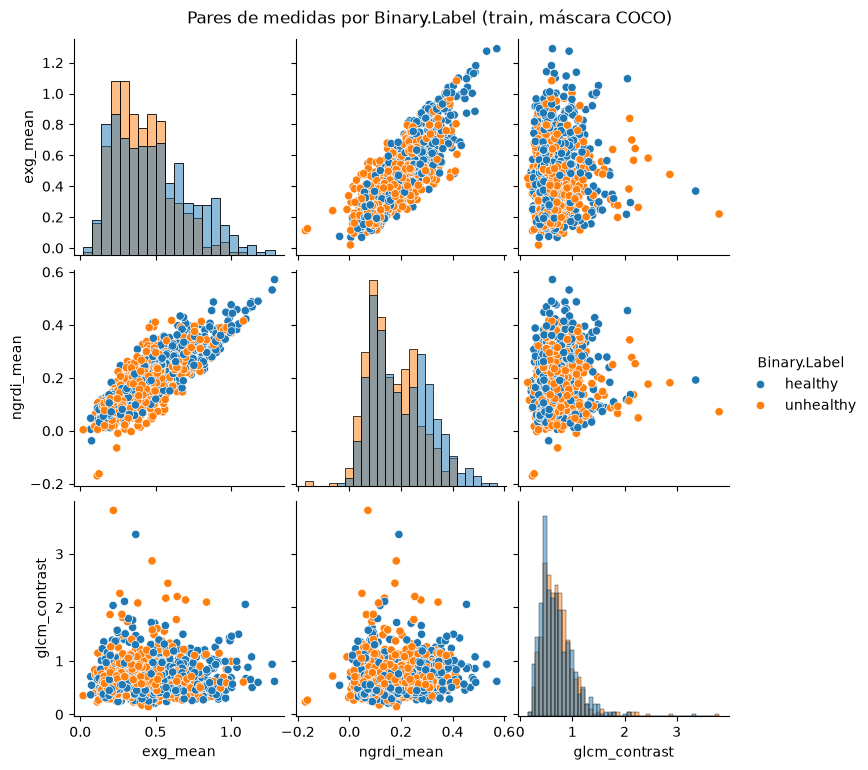

figura: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole-featured-masked-feature-pairs.png


WindowsPath('D:/Maestria/Documentos/Proyecto de innovación tecnologica en IA/Desarrollo/diagnostico-hojas-cafe/experiments/results/rocole-featured-masked-feature-pairs.png')

In [36]:
# correlation_leaves, pair_feature_columns, results_dir

pair_plot_data = correlation_leaves[pair_feature_columns].copy()
pair_plot_data["Binary.Label"] = correlation_leaves["binary_label_code"].map(
    {0: "healthy", 1: "unhealthy"}
)
pair_grid = sns.pairplot(
    pair_plot_data,
    vars=pair_feature_columns,
    hue="Binary.Label",
    diag_kind="hist",
)
pair_grid.fig.suptitle("Pares de medidas por Binary.Label (train, máscara COCO)", y=1.02)
feature_pairs_path = results_dir / "rocole-featured-masked-feature-pairs.png"
pair_grid.savefig(feature_pairs_path, dpi=120, bbox_inches="tight")
plt.show()

print("figura:", feature_pairs_path)
feature_pairs_path


Observa si las nubes de sana y afectada se mezclan. El solape visual sigue siendo el mensaje, no un ranking.


## Conclusiones

Inventario masked: 1481 filas y 0 errores de extracción. VARI sigue inestable en train (percentiles extremos, mínimo y máximo enormes): drop_vari queda confirmado; el baseline masked usa las 7 columnas sin VARI.

Correlación con Binary.Label en train (masked): glcm_homogeneity alrededor de -0.25, glcm_energy alrededor de -0.22, ngrdi_mean y exg_mean alrededor de -0.17. La señal se ve un poco más clara en textura que en el 03 full-image, pero el solape entre hoja sana y afectada sigue ahí: no hay victoria que declarar.

Siguiente paso: 04-masked.
